### TH 5.1: Dựng tam giác Pascal

Dựng tam giác Pascal 10 hàng trong ma trận số nguyên $10 \times 10$ bằng slicing (mỗi hàng tính từ hàng trước bằng một phép cộng vector, không dùng vòng lặp lồng):
$$P_{i,j} = P_{i-1,j} + P_{i-1,j-1}, \quad P_{i,0} = 1$$
In hàng 4 và hàng 9; kiểm tra $\binom{9}{4} = 126$ và tổng hàng 9 bằng $2^9$.

In [17]:
import numpy as np

P = np.zeros((10, 10), dtype=int)
P[:, 0] = 1

for i in range(1, 10):
    P[i, 1:] = P[i-1, 1:] + P[i-1, :-1]

print(P[4])
print(P[9])
assert P[9, 4] == 126
assert P[9].sum() == 512
display(P)

[1 4 6 4 1 0 0 0 0 0]
[  1   9  36  84 126 126  84  36   9   1]


array([[  1,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  1,   1,   0,   0,   0,   0,   0,   0,   0,   0],
       [  1,   2,   1,   0,   0,   0,   0,   0,   0,   0],
       [  1,   3,   3,   1,   0,   0,   0,   0,   0,   0],
       [  1,   4,   6,   4,   1,   0,   0,   0,   0,   0],
       [  1,   5,  10,  10,   5,   1,   0,   0,   0,   0],
       [  1,   6,  15,  20,  15,   6,   1,   0,   0,   0],
       [  1,   7,  21,  35,  35,  21,   7,   1,   0,   0],
       [  1,   8,  28,  56,  70,  56,  28,   8,   1,   0],
       [  1,   9,  36,  84, 126, 126,  84,  36,   9,   1]])

### TH 5.6: Giải hệ phương trình tuyến tính

Cho $A = \begin{pmatrix} 2 & 1 & -1 & 0 \\ 1 & 3 & 2 & 1 \\ 0 & -1 & 4 & 2 \\ 3 & 0 & 1 & 5 \end{pmatrix}$ và véc tơ nghiệm biết trước $x^* = (1, -1, 2, 3)^\top$.
Đặt $b = Ax^*$, giải lại hệ bằng `np.linalg.solve`, kiểm chứng bằng `np.allclose`. Sau đó thay hàng 4 của $A$ bằng tổng hàng 1 và hàng 2 và ghi lại lỗi của solve.

In [18]:
import numpy as np

A = np.array([
    [2, 1, -1, 0],
    [1, 3, 2, 1],
    [0, -1, 4, 2],
    [3, 0, 1, 5]
], dtype=float)

x_star = np.array([1, -1, 2, 3], dtype=float)
b = A @ x_star

x = np.linalg.solve(A, b)
print(x)
print(np.allclose(x, x_star))

A[3] = A[0] + A[1]
try:
    np.linalg.solve(A, b)
except np.linalg.LinAlgError as e:
    print(e)

[ 1. -1.  2.  3.]
True


### TH 5.7: Đa thức nội suy đi qua bốn điểm

Đa thức bậc 3 đi qua bốn điểm $(0,1)$, $(1,0)$, $(2,5)$, $(3,22)$ là duy nhất. Tìm các hệ số $c_0, \dots, c_3$ của $p(x) = c_0 + c_1x + c_2x^2 + c_3x^3$ bằng cách giải hệ với ma trận Vandermonde (`np.vander(x, increasing=True)`), kiểm tra bằng `allclose`, rồi tính $p(1.5)$.

In [19]:
import numpy as np

x = np.array([0, 1, 2, 3], dtype=float)
y = np.array([1, 0, 5, 22], dtype=float)

V = np.vander(x, increasing=True)
c = np.linalg.solve(V, y)
print(c)
assert np.allclose(V @ c, y)

p = c[0] + c[1]*1.5 + c[2]*(1.5**2) + c[3]*(1.5**3)
print(p)

[ 1. -2. -0.  1.]
1.375


### TH 5.8: So sánh hiệu năng của solve và nghịch đảo ma trận

Với ma trận ngẫu nhiên $500 \times 500$ (`default_rng(0)`) và véc tơ $b$ ngẫu nhiên, giải $Ax=b$ bằng `solve` và bằng `inv(A) @ b`. So sánh phần dư $\|Ax-b\|$ và thời gian của hai cách; kiểm tra bằng `assert` cả hai nghiệm đều đạt phần dư rất nhỏ và giống nhau.

In [20]:
import numpy as np
import time

rng = np.random.default_rng(0)
A = rng.random((500, 500))
b = rng.random(500)

t0 = time.time()
x1 = np.linalg.solve(A, b)
t1 = time.time()
d1 = t1 - t0
r1 = np.linalg.norm(A @ x1 - b)

t0 = time.time()
x2 = np.linalg.inv(A) @ b
t1 = time.time()
d2 = t1 - t0
r2 = np.linalg.norm(A @ x2 - b)

print(d1, r1)
print(d2, r2)
assert r1 < 1e-10 and r2 < 1e-10
assert np.allclose(x1, x2)

0.06093907356262207 8.058540555394598e-13
0.0855553150177002 2.3621299704879234e-12


### TH 6.2: Chương trình nhập danh sách sinh viên

Viết chương trình nhập danh sách sinh viên (họ tên, mã sinh viên, ngày sinh dạng dd/mm/yyyy) từ bàn phím, dừng khi người dùng bỏ trống họ tên. Lưu vào một DataFrame, chuyển ngày sinh sang kiểu thời gian bằng `pd.to_datetime(..., format="%d/%m/%Y")`, tính cột Tuoi (số năm nguyên) từ ngày sinh đến mốc 01/01/2026, ghi ra `students.xlsx` và đọc lại để kiểm tra.

In [ ]:
import pandas as pd

ds = []
while True:
    name = input("Ho ten: ").strip()
    if not name:
        break
    msv = input("MSV: ").strip()
    ns = input("Ngay sinh (dd/mm/yyyy): ").strip()
    ds.append({"HoTen": name, "MSV": msv, "NgaySinh": ns})

if ds:
    df = pd.DataFrame(ds)
    df["NgaySinh"] = pd.to_datetime(df["NgaySinh"], format="%d/%m/%Y")
    df["Tuoi"] = ((pd.Timestamp("2026-01-01") - df["NgaySinh"]).dt.days / 365.25).astype(int)
    df.to_excel("students.xlsx", index=False)
    display(pd.read_excel("students.xlsx"))

### TH 6.3: Phân tích chỉ số cơ thể của 200 người

Với `data/200heightsweights.csv`:
1. Đổi tên cột thành `Height_in`, `Weight_lb`, đổi sang cm và kg, điền ô thiếu bằng trung bình cột, tính BMI bằng method chaining.
2. Đếm số người có $BMI < 18.5$.
3. Dùng `pd.cut` chia chiều cao thành ba nhóm: Thap ($<170$), Trung binh ($[170, 175)$), Cao ($\ge 175$) và đếm.
4. Dùng `groupby` tính tỉ lệ người có $BMI < 18.5$ trong từng nhóm.
5. Vẽ boxplot cân nặng theo nhóm chiều cao bằng Seaborn.

19
Nhom_Chieu_Cao
Thap          75
Cao           70
Trung binh    55
Name: count, dtype: int64
Nhom_Chieu_Cao
Thap          0.013333
Trung binh    0.072727
Cao           0.200000
Name: Is_Underweight, dtype: float64


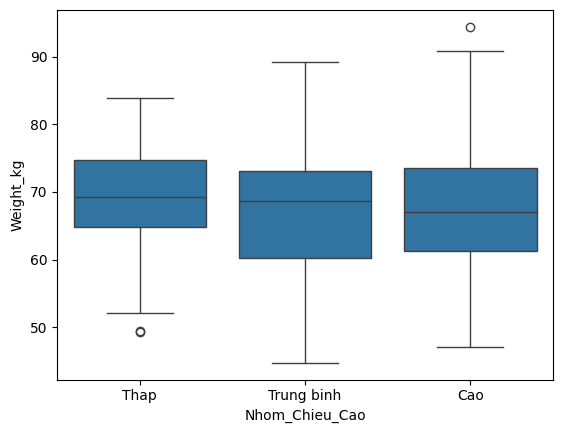

In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

os.makedirs("data", exist_ok=True)
if not os.path.exists("data/200heightsweights.csv"):
    rng = np.random.default_rng(42)
    h = rng.normal(68, 3, 200)
    w = rng.normal(150, 20, 200)
    pd.DataFrame({"Height": h, "Weight": w}).to_csv("data/200heightsweights.csv", index=False)

df = (pd.read_csv("data/200heightsweights.csv")
      .rename(columns={"Height": "Height_in", "Weight": "Weight_lb"})
      .assign(Height_in=lambda d: d["Height_in"].fillna(d["Height_in"].mean()),
              Weight_lb=lambda d: d["Weight_lb"].fillna(d["Weight_lb"].mean()))
      .assign(Height_cm=lambda d: d["Height_in"] * 2.54,
              Weight_kg=lambda d: d["Weight_lb"] * 0.45359237)
      .assign(BMI=lambda d: d["Weight_kg"] / ((d["Height_cm"] / 100) ** 2)))

print((df["BMI"] < 18.5).sum())

df["Nhom_Chieu_Cao"] = pd.cut(df["Height_cm"], bins=[-np.inf, 170, 175, np.inf], labels=["Thap", "Trung binh", "Cao"])
print(df["Nhom_Chieu_Cao"].value_counts())

df["Is_Underweight"] = df["BMI"] < 18.5
print(df.groupby("Nhom_Chieu_Cao", observed=False)["Is_Underweight"].mean())

sns.boxplot(data=df, x="Nhom_Chieu_Cao", y="Weight_kg")
plt.savefig("box.png")
plt.show()

### TH 6.4: Thống kê phòng ban và lương nhân viên

Với `data/core_HRdata.csv`:
1. Làm sạch tên phòng ban bằng `.str.strip()`.
2. Lập bảng lương trung bình theo phòng ban và giới tính bằng `groupby` và `unstack`.
3. Chuyển `Date of Hire` sang kiểu thời gian, tính `Tham_nien` đến 01/01/2017 và in 5 nhân viên thâm niên cao nhất.
4. Thống kê số nhân viên theo `Performance Score`.

In [25]:
import pandas as pd
import os

os.makedirs("data", exist_ok=True)
if not os.path.exists("data/core_HRdata.csv"):
    data = {
        "Employee_Name": ["An", "Binh", "Chi", "Dong", "Em"],
        "Department": [" Production  ", "IT Support", "Production", "Software Engineering", "Sales"],
        "Sex": ["F", "M", "F", "M", "F"],
        "Pay Rate": [25.0, 30.0, 22.0, 45.0, 28.0],
        "Date of Hire": ["2010-05-10", "2015-08-15", "2008-03-20", "2012-11-01", "2016-04-05"],
        "Performance Score": ["Fully Meets", "Fully Meets", "Exceeds", "Fully Meets", "Needs Improvement"]
    }
    pd.DataFrame(data).to_csv("data/core_HRdata.csv", index=False)

df = pd.read_csv("data/core_HRdata.csv")
df["Department"] = df["Department"].str.strip()

print(df.groupby(["Department", "Sex"])["Pay Rate"].mean().unstack())

df["Date of Hire"] = pd.to_datetime(df["Date of Hire"])
df["Tham_nien"] = (pd.Timestamp("2017-01-01") - df["Date of Hire"]).dt.days // 365

display(df.sort_values(by=["Tham_nien", "Employee_Name"], ascending=[False, True]).head(5)[["Employee_Name", "Tham_nien"]])
print(df["Performance Score"].value_counts())

Sex                      F     M
Department                      
IT Support             NaN  30.0
Production            23.5   NaN
Sales                 28.0   NaN
Software Engineering   NaN  45.0


,Employee_Name,Tham_nien
2,Chi,8
0,An,6
3,Dong,4
1,Binh,1
4,Em,0


Performance Score
Fully Meets          3
Exceeds              1
Needs Improvement    1
Name: count, dtype: int64
